# Nhóm 22 · Thực nghiệm ghép ảnh V0 và V1

Notebook chạy **V0 tuần tự** và **V1 CUDA** trong cùng phiên Colab, trên cùng mã nguồn và dữ liệu. Kết quả gồm đối chiếu từng stage, benchmark 12 cặp thật và 1 cặp synthetic, biểu đồ speedup và ảnh ghép cạnh nhau.

1. Đợi Google Drive đồng bộ mã mới trong **A:\PP\image-stitching**. Notebook dùng thư mục **/content/drive/Othercomputers/My Laptop/image-stitching**. Nếu thư mục đổi tên, sửa biến SOURCE_PROJECT.
2. Mở lại bản notebook đã đồng bộ trong Colab, chọn **Runtime → Change runtime type → T4 GPU**, rồi chọn **Run all**. Cấp quyền Drive khi được hỏi.
3. Notebook sao chép mã và dữ liệu vào ổ tạm Colab trước khi build và chạy. Mặc định mỗi cấu hình warmup một lần và đo năm lần. Nếu chỉ muốn thử V1, có thể dừng sau ô build và thử một cặp ảnh.

Tệp ZIP kết quả ở cuối notebook gồm báo cáo, CSV từng lần đo, log và panorama.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import os
import platform
import shutil
import subprocess
import sys
import tempfile
import zipfile

SOURCE_PROJECT = Path("/content/drive/Othercomputers/My Laptop/image-stitching")
RUNS = 5
WARMUP = 1
RUN_BACKEND_ERROR_TESTS = True
CUDA_ARCH = None  # Tự nhận từ GPU; dùng "sm_75" để chỉ định T4.

if not SOURCE_PROJECT.is_dir():
    raise FileNotFoundError(f"Không thấy {SOURCE_PROJECT}. Kiểm tra ô mount và đường dẫn Drive.")
required = ("src/gpu_pipeline.cu", "tools/verify_v1.py", "tools/benchmark.py", "requirements.txt", "dataset")
missing = [name for name in required if not (SOURCE_PROJECT / name).exists()]
if missing:
    raise FileNotFoundError(f"Drive chưa có các mục: {', '.join(missing)}. Đợi đồng bộ mã và dữ liệu.")
if RUNS < 5 or WARMUP < 1:
    raise ValueError("Thực nghiệm cần ít nhất 5 lần đo và 1 warmup.")

def capture(*cmd):
    return subprocess.check_output(cmd, text=True, stderr=subprocess.STDOUT).strip()

if not shutil.which("nvidia-smi") or not shutil.which("nvcc"):
    raise RuntimeError("Chọn GPU runtime có NVIDIA CUDA Toolkit (nvidia-smi và nvcc).")
try:
    gpu_info = capture("nvidia-smi", "-L")
    capability = capture("nvidia-smi", "--query-gpu=compute_cap", "--format=csv,noheader").splitlines()[0]
except (subprocess.CalledProcessError, IndexError) as error:
    raise RuntimeError("Colab chưa nhận được GPU. Kiểm tra lại loại runtime.") from error

if CUDA_ARCH is None:
    CUDA_ARCH = "sm_" + capability.strip().replace(".", "")
nvcc_info = capture("nvcc", "--version")
print(gpu_info, "\n", nvcc_info, "\nCUDA_ARCH:", CUDA_ARCH, sep="")

ROOT = Path(tempfile.mkdtemp(prefix="group22-v0-v1-", dir="/content"))
ignore = shutil.ignore_patterns("__pycache__", ".ipynb_checkpoints", "*.exe", "*.obj", "*.o")
print("Đang sao chép dự án từ:", SOURCE_PROJECT, flush=True)
for name in ("src", "tools"):
    shutil.copytree(SOURCE_PROJECT / name, ROOT / name, ignore=ignore)
shutil.copy2(SOURCE_PROJECT / "requirements.txt", ROOT / "requirements.txt")
(ROOT / "dataset").mkdir()
for name in ("raw", "prepared", "synthetic"):
    source_folder = SOURCE_PROJECT / "dataset" / name
    if source_folder.is_dir():
        shutil.copytree(source_folder, ROOT / "dataset" / name, ignore=ignore)
    else:
        (ROOT / "dataset" / name).mkdir()

digest = hashlib.sha256()
for item in sorted(ROOT.rglob("*")):
    if item.is_file():
        digest.update(item.relative_to(ROOT).as_posix().encode("utf-8") + b"\0")
        file_digest = hashlib.sha256()
        with item.open("rb") as stream:
            for block in iter(lambda: stream.read(1024 * 1024), b""):
                file_digest.update(block)
        digest.update(file_digest.digest())

EVIDENCE = ROOT / "experiment"
EVIDENCE.mkdir()
ENV = {**os.environ, "NO_COLOR": "1"}
metadata = {
    "started_utc": datetime.now(timezone.utc).isoformat(),
    "source_project": str(SOURCE_PROJECT),
    "snapshot_sha256": digest.hexdigest(),
    "gpu": gpu_info,
    "cuda_arch": CUDA_ARCH,
    "nvcc": nvcc_info,
    "python": sys.version,
    "platform": platform.platform(),
    "runs": RUNS,
    "warmup": WARMUP,
}
(EVIDENCE / "session.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Thư mục chạy:", ROOT)

def run(*args, check=True, cwd=ROOT):
    return subprocess.run([str(arg) for arg in args], cwd=cwd, env=ENV, check=check).returncode

GPU 0: Tesla T4 (UUID: GPU-4372ba52-f7f9-9e72-fb0e-760ed59d4eb3)
nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0
CUDA_ARCH:sm_75
Đang sao chép dự án từ: /content/drive/Othercomputers/My Laptop/image-stitching
Thư mục chạy: /content/group22-v0-v1-xwxn2sjy



## Build và thử một cặp ảnh

Bản CUDA duy nhất dùng để chạy cả V0 và V1. Nếu thư mục Drive chỉ có ảnh raw, notebook chuẩn bị lại 24 ảnh PNG. Nếu thiếu cặp synthetic, notebook tạo cặp từ HEIC hoặc dùng fixture tự sinh có độ dịch đã biết.

V0 · 2405 × 1298


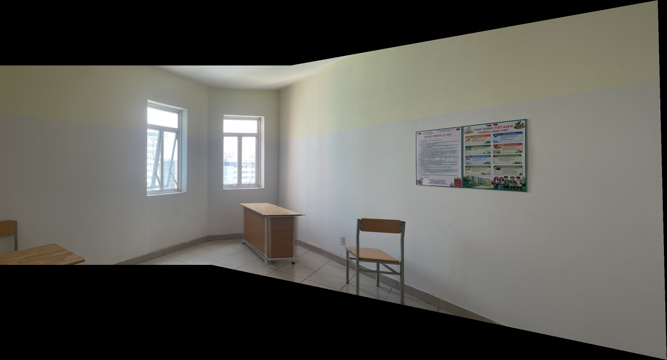

V1 · 2405 × 1298


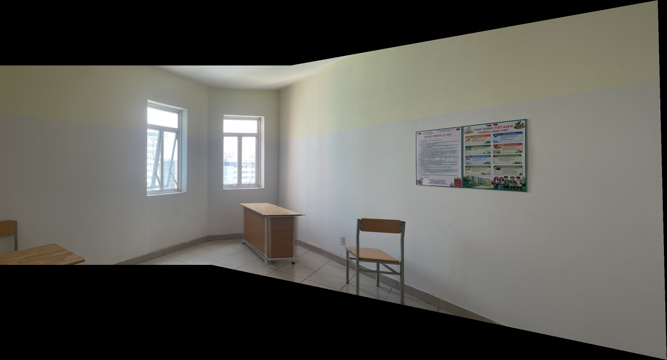

In [3]:
from IPython.display import display

run(sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt", "pandas")
from PIL import Image
sys.path.insert(0, str(ROOT / "tools"))
from benchmark import SITES

RESOLUTIONS = ("small", "medium", "large")
prepared = [ROOT / "dataset/prepared" / size / f"{site}_{side}.png"
            for size in RESOLUTIONS for site in SITES for side in ("left", "right")]
synthetic_root = ROOT / "dataset/synthetic"
synthetic_files = [synthetic_root / name for name in
                   ("synthetic_left.png", "synthetic_right.png", "H_ground_truth.txt")]
if any(not path.is_file() for path in prepared):
    run(sys.executable, "tools/prepare_dataset.py")
elif any(not path.is_file() for path in synthetic_files):
    run(sys.executable, "tools/prepare_dataset.py", "--synthetic-only")
missing = [str(path.relative_to(ROOT)) for path in prepared + synthetic_files if not path.is_file()]
if missing:
    raise FileNotFoundError(f"Thiếu ảnh thực nghiệm: {', '.join(missing)}")

run(sys.executable, "tools/build.py", "--cuda", "--arch", CUDA_ARCH)
BINARY = ROOT / "stitch"
pair = ROOT / "dataset/prepared/small"
for version in (0, 1):
    panorama = EVIDENCE / f"smoke_v{version}.png"
    run(BINARY, pair / "site1_indoor_left.png", pair / "site1_indoor_right.png", panorama,
        "--version", version, "--runs", 1)
    with Image.open(panorama) as image:
        preview = image.copy()
        preview.thumbnail((960, 360))
        print(f"V{version} · {image.width} × {image.height}")
        display(preview)


## Đối chiếu và đo hiệu năng

Bộ kiểm tra đối chiếu ảnh đã làm mờ, keypoint theo đúng thứ tự, BRIEF, match, tập inlier, H, canvas, seam và pixel. Bảng benchmark dùng thời gian từ hai ảnh RGB trong RAM đến panorama trong RAM. Chi phí H2D và D2H của V1 được trình bày riêng.

In [4]:
verification_file = EVIDENCE / "verification.json"
verification_file.unlink(missing_ok=True)
exit_codes = {
    "verify_v1": run(sys.executable, "tools/verify_v1.py", "--report", verification_file, check=False),
}
if not verification_file.is_file():
    raise RuntimeError("Lệnh đối chiếu dừng trước khi tạo báo cáo. Xem log ở trên.")
verification = json.loads(verification_file.read_text(encoding="utf-8"))

if RUN_BACKEND_ERROR_TESTS:
    exit_codes["make_test_backend"] = run("make", "test-backend", f"CUDA_ARCH={CUDA_ARCH}",
                                         cwd=ROOT / "src", check=False)
    if exit_codes["make_test_backend"] == 0:
        exit_codes["test_backend_errors"] = run(ROOT / "src/test_backend", "--check-errors", check=False)

reports = {}
for version in (0, 1):
    print(f"\n=== Benchmark V{version} ===", flush=True)
    summary = ROOT / f"outputs_v{version}/summary.json"
    summary.unlink(missing_ok=True)
    exit_codes[f"benchmark_v{version}"] = run(sys.executable, "tools/benchmark.py", "--version", version,
                                              "--runs", RUNS, "--warmup", WARMUP, check=False)
    if summary.is_file():
        reports[version] = json.loads(summary.read_text(encoding="utf-8"))

(EVIDENCE / "exit_codes.json").write_text(json.dumps(exit_codes, indent=2), encoding="utf-8")
if len(reports) != 2:
    raise RuntimeError(f"Thiếu summary của benchmark. Mã thoát: {exit_codes}")
print("Trạng thái lệnh:", exit_codes)


=== Benchmark V0 ===

=== Benchmark V1 ===
Trạng thái lệnh: {'verify_v1': 0, 'make_test_backend': 0, 'test_backend_errors': 0, 'benchmark_v0': 0, 'benchmark_v1': 0}



## Kết quả

Speedup được tính bằng thời gian V0 chia cho V1 của cùng cặp. Bảng chỉ tính speedup khi hai lần benchmark thành công và đối chiếu đạt. Các cặp lỗi vẫn xuất hiện để dễ tìm nguyên nhân.

,case,verification,v0_ms,v1_ms,speedup,h2d_ms,d2h_ms,projection_mean_px,max_pixel_delta,error
0,small/site1_indoor,PASS,182.2939,11.5491,15.7842,1.2945,1.9895,0.0,0,
1,small/site2_outdoor,PASS,238.8269,8.7432,27.3156,1.1997,0.9094,0.0,0,
2,small/site3_custom,PASS,223.4406,8.2720,27.0116,1.6105,1.4971,0.0,0,
3,small/site4_challenging,PASS,2242.0528,21.9513,102.1377,1.2032,1.7856,0.0,0,
4,medium/site1_indoor,PASS,423.1052,17.1975,24.6027,3.2011,4.5764,0.0,0,
5,medium/site2_outdoor,PASS,439.7389,16.4671,26.7040,2.7429,1.9942,0.0,0,
6,medium/site3_custom,PASS,390.6233,14.1056,27.6928,2.6603,2.7544,0.0,0,
7,medium/site4_challenging,PASS,3003.3582,37.6694,79.7293,2.7938,4.0456,0.0,0,
8,large/site1_indoor,PASS,1715.4062,55.0397,31.1667,10.7960,17.4470,0.0,0,
9,large/site2_outdoor,PASS,2474.1140,39.0578,63.3450,11.1851,7.8898,0.0,0,


Ca descriptor rỗng: PASS
Synthetic · sai số chiếu trung bình của V1 so với GT: 9.4272e-12 px


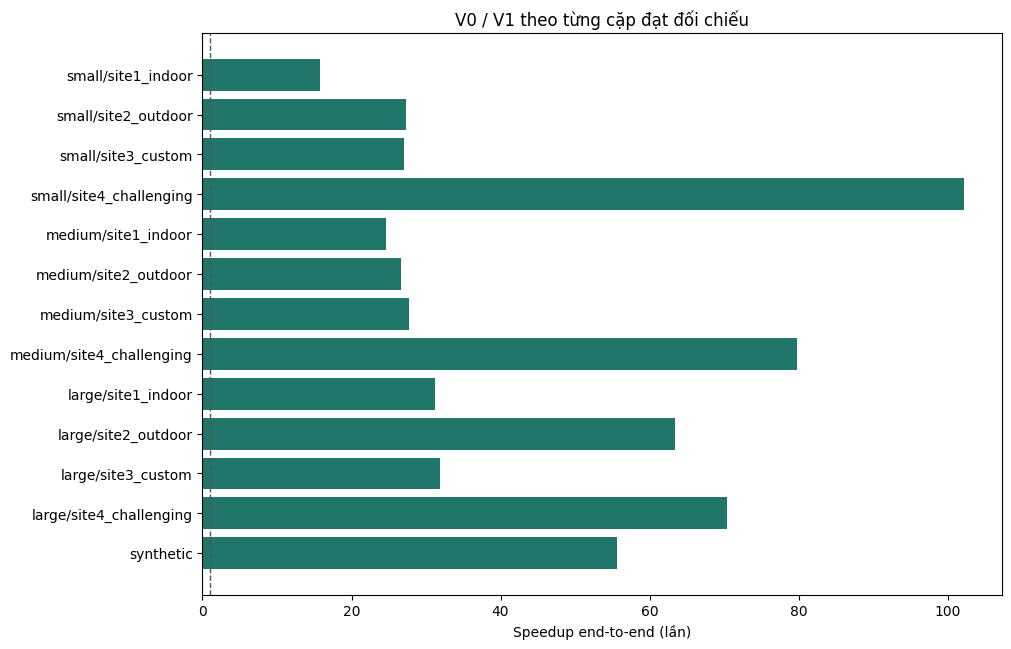

,resolution,version,pairs,preprocess_ms,keypoint_ms,descriptor_ms,matching_ms,ransac_ms,warp_blend_ms
0,small,0,4,29.125,106.338,2.528,437.908,8.065,137.668
1,small,1,4,0.202,0.291,0.252,0.673,2.949,5.358
2,medium,0,4,56.996,269.802,3.227,456.190,7.027,270.942
3,medium,1,4,0.422,0.482,0.288,0.786,2.797,10.362
4,large,0,4,235.932,1164.912,5.728,784.267,10.133,1185.020
5,large,1,4,1.371,1.219,0.297,1.084,2.407,32.760


In [5]:
import matplotlib.pyplot as plt
import pandas as pd

def case_results(report):
    cases = {f"{r['resolution']}/{r['site']}": r for r in report["results"]}
    return {**cases, "synthetic": report["correctness"]}

v0, v1 = (case_results(reports[version]) for version in (0, 1))
rows = []
for case in [f"{size}/{site}" for size in RESOLUTIONS for site in SITES] + ["synthetic"]:
    a, b = v0.get(case, {}), v1.get(case, {})
    check = verification.get(case, {})
    v0_ms = a.get("mean", {}).get("total_pipeline_ms") if a.get("success") else None
    v1_mean = b.get("mean", {}) if b.get("success") else {}
    v1_ms = v1_mean.get("total_pipeline_ms")
    rows.append({
        "case": case,
        "verification": "PASS" if check.get("passed") else "FAIL" if check else "Chưa có",
        "v0_ms": v0_ms,
        "v1_ms": v1_ms,
        "speedup": v0_ms / v1_ms if check.get("passed") and v0_ms is not None and v1_ms else None,
        "h2d_ms": v1_mean.get("h2d_ms"),
        "d2h_ms": v1_mean.get("d2h_ms"),
        "projection_mean_px": check.get("projection_mean_px"),
        "max_pixel_delta": check.get("max_pixel_delta"),
        "error": check.get("error") or ", ".join(check.get("mismatches", []))
                 or a.get("error") or b.get("error") or "",
    })

table = pd.DataFrame(rows)
table.to_csv(EVIDENCE / "v0_v1_comparison.csv", index=False)
display(table.round(4))
empty = verification.get("empty_descriptors", {})
synthetic = verification.get("synthetic", {})
print(f"Ca descriptor rỗng: {'PASS' if empty.get('passed') else 'FAIL'}")
if "ground_truth_mean_px" in synthetic:
    print(f"Synthetic · sai số chiếu trung bình của V1 so với GT: {synthetic['ground_truth_mean_px']:.6g} px")

chart = table.dropna(subset=["speedup"])
if not chart.empty:
    fig, ax = plt.subplots(figsize=(10, 0.36 * len(chart) + 1.7), layout="constrained")
    ax.barh(chart["case"], chart["speedup"], color="#1f7669")
    ax.axvline(1, color="#555555", linestyle="--", linewidth=1)
    ax.invert_yaxis()
    ax.set_xlabel("Speedup end-to-end (lần)")
    ax.set_title("V0 / V1 theo từng cặp đạt đối chiếu")
    fig.savefig(EVIDENCE / "speedup.png", dpi=150)
    plt.show()

stage_names = ("preprocess_ms", "keypoint_ms", "descriptor_ms", "matching_ms", "ransac_ms", "warp_blend_ms")
stages = []
for size in RESOLUTIONS:
    valid = [row["case"] for row in rows if row["case"].startswith(size + "/") and row["speedup"] is not None]
    for version, results in ((0, v0), (1, v1)):
        if valid:
            stages.append({"resolution": size, "version": version, "pairs": len(valid),
                           **{stat: sum(results[key]["mean"][stat] for key in valid) / len(valid)
                              for stat in stage_names}})
stage_table = pd.DataFrame(stages)
stage_table.to_csv(EVIDENCE / "stages_by_resolution.csv", index=False)
display(stage_table.round(3))

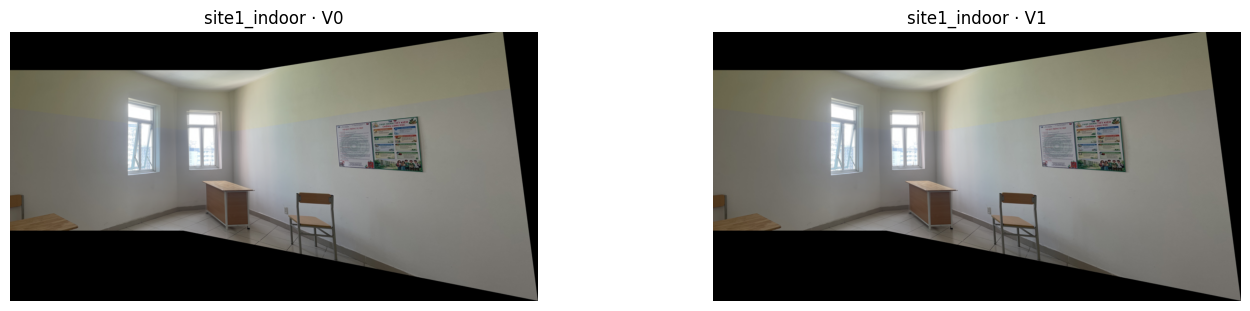

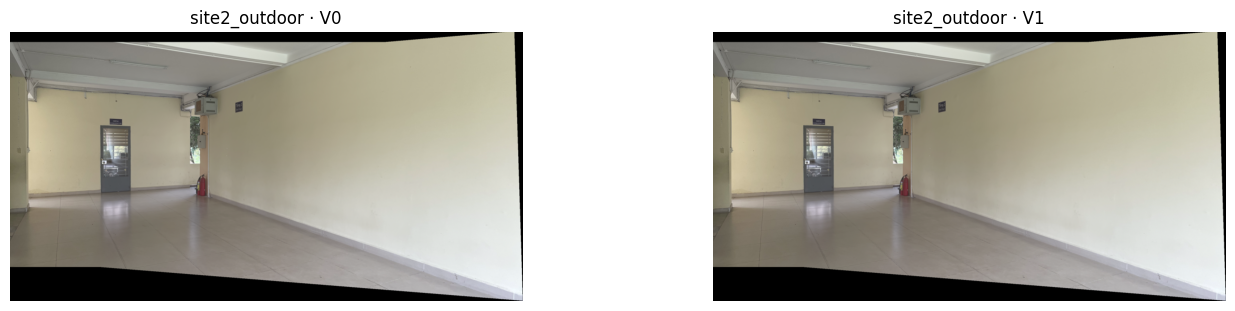

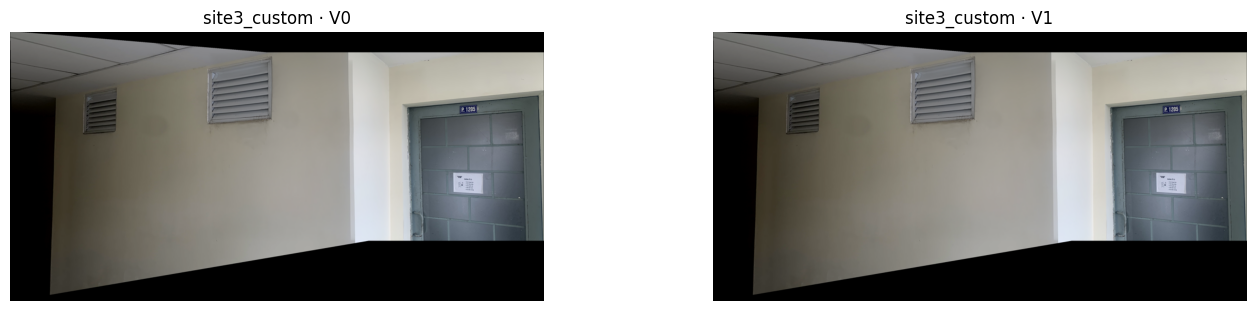

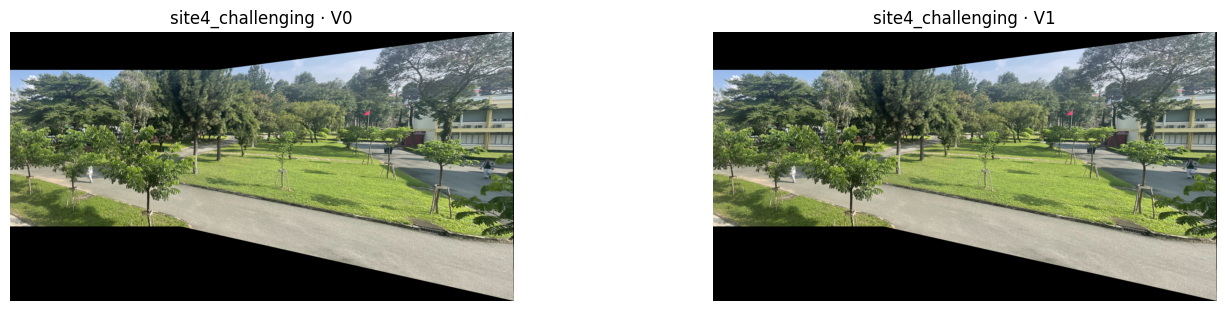

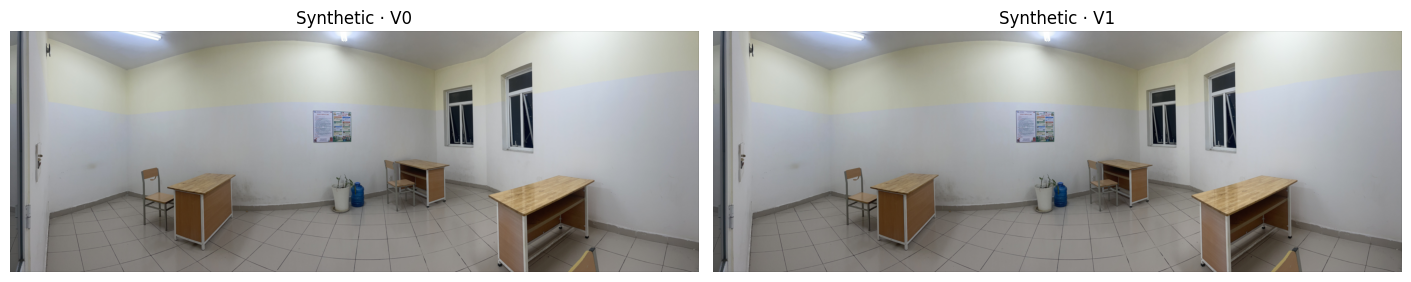

In [6]:
medium_cases = [(site, f"panorama_{site}.png") for site in SITES]
for label, filename in medium_cases + [("Synthetic", "synthetic_panorama.png")]:
    fig, axes = plt.subplots(1, 2, figsize=(14, 3), layout="constrained")
    for version, ax in enumerate(axes):
        path = ROOT / f"outputs_v{version}" / filename
        if path.is_file():
            with Image.open(path) as image:
                preview = image.copy()
                preview.thumbnail((1400, 500))
                ax.imshow(preview)
            ax.set_title(f"{label} · V{version}")
        else:
            ax.set_title(f"{label} · V{version} chưa có panorama")
        ax.axis("off")
    plt.show()


## Lưu kết quả

Sau khi chạy xong, tải ZIP từ thanh **Files** trong Colab. ZIP chứa báo cáo đối chiếu, môi trường chạy, bảng speedup, CSV từng lượt đo, log và ảnh ghép của cả hai phiên bản.

In [7]:
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
archive = Path(f"/content/Group22_V0_V1_{stamp}.zip")
with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
    for folder in (EVIDENCE, ROOT / "outputs_v0", ROOT / "outputs_v1"):
        for path in sorted(folder.rglob("*")):
            if path.is_file():
                bundle.write(path, arcname=path.relative_to(ROOT))
print(f"Tải tệp trong tab Files: {archive}")
# from google.colab import files
# files.download(str(archive))

Tải tệp trong tab Files: /content/Group22_V0_V1_20261125T093830Z.zip
